# Validation strategy

**Objective:** choose the evaluation framework used for the rest of the project.

Competition score = **0.60 x F1 + 0.40 x ROC-AUC**.

Questions answered here:

1. Is a random split representative of the Test set, or is a location-grouped split needed?
2. Does time require special treatment?
3. How stable is the score across folds?
4. Should the threshold stay at 0.5 or be optimised?

Reusable code lives in `src/` (metrics, folds, cross-validation), so other
notebooks import it instead of running this notebook with `%run`.

## Imports

In [1]:
import sys
from pathlib import Path

# Make the project root importable (the notebook runs from notebooks/)
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.config import LOCATION_COL, TARGET, TEST_MERGED, TRAIN_MERGED
from src.features import prepare_features
from src.metrics import competition_score, find_best_threshold
from src.models import make_builder
from src.validation import cross_validate, evaluate_oof, make_folds

pd.set_option("display.width", 150)

## Load data

In [2]:
train = pd.read_csv(TRAIN_MERGED)
test = pd.read_csv(TEST_MERGED)

y = train[TARGET]
print("Train:", train.shape, "| Test:", test.shape)
print("Positive rate:", round(y.mean(), 3))

Train: (3146, 30) | Test: (1030, 29)
Positive rate: 0.651


## Reference point: trivial predictor

Predicting the positive class for everyone gives a non-trivial F1 when the
positive class is the majority. Any model must be judged against this value.

In [3]:
trivial = competition_score(y, [1.0] * len(y), threshold=0.5)
print({k: round(v, 4) for k, v in trivial.items()})

{'F1': 0.7884, 'ROC_AUC': 0.5, 'Competition_Score': 0.673}


## Does geography matter?

Share of Test rows that belong to a location also present in Train.

In [4]:
train_locations = set(train[LOCATION_COL])
overlap = test[LOCATION_COL].isin(train_locations).mean()

print("Train locations:", len(train_locations))
print("Test locations:", test[LOCATION_COL].nunique())
print(f"Test rows in locations seen in train: {overlap:.1%}")
print("Train date range:", train["deathdate"].min(), "->", train["deathdate"].max())
print("Test date range: ", test["deathdate"].min(), "->", test["deathdate"].max())

Train locations: 39
Test locations: 11
Test rows in locations seen in train: 2.5%
Train date range: 2007-10-02 -> 2022-12-13
Test date range:  2007-11-24 -> 2022-05-17


## Compare validation strategies

Same model and features, three different ways to split the data.
A large gap between strategies would mean that the split, not the model,
drives the score.

In [5]:
X = prepare_features(train, feature_set="base", drop_location_features=True)
builder = make_builder("catboost", X, {"iterations": 300, "learning_rate": 0.05, "depth": 5})

strategies = {
    "stratified": make_folds(y, "stratified"),
    "group": make_folds(y, "group", groups=train[LOCATION_COL]),
    "time": make_folds(y, "time", dates=train["deathdate"]),
}

results, rows = {}, []
for name, folds in strategies.items():
    results[name] = cross_validate(builder, X, y, folds)
    m = evaluate_oof(y, results[name])
    rows.append({
        "strategy": name,
        "rows_scored": m["n_scored"],
        "threshold": m["threshold"],
        "F1": round(m["F1"], 4),
        "ROC_AUC": round(m["ROC_AUC"], 4),
        "score": round(m["score"], 4),
        "score_at_0.5": round(m["score_at_0.5"], 4),
        "fold_auc_std": round(m["fold_auc_std"], 4),
    })

pd.DataFrame(rows)

,strategy,rows_scored,threshold,F1,ROC_AUC,score,score_at_0.5,fold_auc_std
0,stratified,3146,0.43,0.8156,0.8072,0.8123,0.8059,0.0156
1,group,3146,0.38,0.8148,0.8098,0.8128,0.8030,0.0118
2,time,2620,0.37,0.7906,0.7713,0.7829,0.7810,0.0837


## Fold stability (grouped validation)

AUC per fold. A large spread means that single-split scores are unreliable.

In [6]:
fold_auc = pd.Series(results["group"]["fold_auc"], name="fold_auc")
fold_auc.index = [f"fold_{i + 1}" for i in range(len(fold_auc))]
display(fold_auc.round(4).to_frame())
print(f"Mean {fold_auc.mean():.4f} | Std {fold_auc.std():.4f}")

,fold_auc
fold_1,0.8190
fold_2,0.7939
fold_3,0.8281
fold_4,0.8071
fold_5,0.8049


Mean 0.8106 | Std 0.0132


## Threshold optimisation

Best threshold:
threshold    0.3800
f1           0.8148
roc_auc      0.8098
score        0.8128
Name: 33, dtype: float64


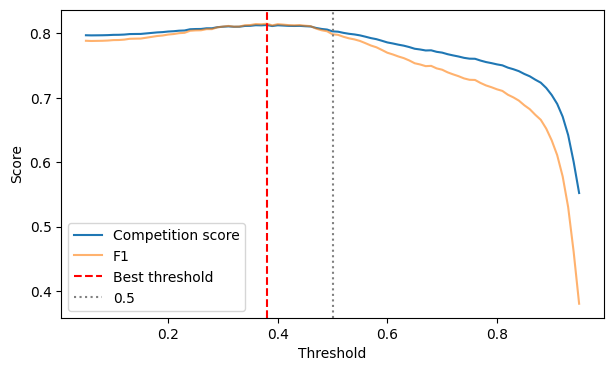

In [7]:
mask = results["group"]["covered"]
best, table = find_best_threshold(y[mask], results["group"]["oof"][mask])

print("Best threshold:")
print(best.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold"], table["score"], label="Competition score")
ax.plot(table["threshold"], table["f1"], label="F1", alpha=0.6)
ax.axvline(best["threshold"], color="red", linestyle="--", label="Best threshold")
ax.axvline(0.5, color="gray", linestyle=":", label="0.5")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.legend()
plt.show()

Threshold chosen inside each fold, to check that the optimum is stable
and not an artefact of one split.

In [8]:
fold_thresholds = []
for i, (_, valid_idx) in enumerate(strategies["group"]):
    fold_best, _ = find_best_threshold(
        y.iloc[valid_idx], results["group"]["oof"][valid_idx]
    )
    fold_thresholds.append({"fold": i + 1, "best_threshold": fold_best["threshold"]})

fold_thresholds = pd.DataFrame(fold_thresholds)
display(fold_thresholds)
print("Std of per-fold thresholds:", round(fold_thresholds["best_threshold"].std(), 3))

,fold,best_threshold
0,1,0.38
1,2,0.25
2,3,0.45
3,4,0.40
4,5,0.46


Std of per-fold thresholds: 0.084


## Decision

- **Main validation: 5-fold grouped by location** (`make_folds(y, "group", groups=location)`).
  Almost all Test rows come from locations absent from Train, so every validation
  fold must also contain only unseen locations.
- Stratified folds are kept only as a comparison.
- Time-based folds score fewer rows (the earliest block is never validated), so their numbers are not directly comparable. They are a robustness check: the Train and Test periods overlap,
  so time does not need to drive the main split.
- **The threshold is optimised** on out-of-fold predictions (more rows, so more
  stable than a single hold-out set) instead of being fixed at 0.5.
- Always compare scores to the trivial predictor above.